# MiBiReMo Example: BTEX dissolution and transport

A 50 m one-dimensional column represents a groundwater flow path within an aquifer, with an average uniform groundwater velocity of 1 m/d. The first 0.5 m of the column contains an immobile non-aqueous phase liquid (NAPL) composed of benzene and ethylbenzene. The NAPL acts as a contaminant source, with both constituents dissolving into the groundwater flowing through the source zone. The dissolved concentrations of benzene (`Benz`) and ethylbenzene (`Ethyl`) are monitored at the column outlet over a simulation period of 100 days.

NAPL dissolution is simulated using two alternative approaches:

1. **Equilibrium approach:** Each NAPL constituent is represented as a separate pure phase using the PHREEQC `EQUILIBRIUM_PHASES` keyword. Consequently, the aqueous phase within the source zone is assumed to remain at equilibrium with the corresponding pure phases, maintaining concentrations at their respective solubility limits.

2. **Kinetic approach:** NAPL dissolution is described by a kinetic rate expression proportional to the difference between the effective solubility and the actual aqueous concentration. The effective solubility is calculated according to Raoult's law, as the product of the mole fraction of each constituent in the NAPL and its pure-component aqueous solubility. Dissolution kinetics are implemented using the PHREEQC `KINETICS` keyword.

The models are implemented using the `ColumnModel` class of MiBiReMo, which computes the advection and dispersion using the semi-Lagrangian solver (`SemiLagSolver`), 
and the reactions with PHREEQC (PhreeqcRM), coupled sequentially at every time step.

To provide a numerical benchmark for the simulations performed with MiBiReMo, the results obtained using the equilibrium approach are compared with those from an independent PHREEQC simulation of the same system, implemented using the `TRANSPORT` keyword. The corresponding input and output files are `pqi/column_BTEX_dissolution.pqi` and `pqi/column_BTEX_dissolution.sel`, respectively.

In [7]:
import math
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import mibiremo as mb

DAY = 86400.0
HERE = Path(__file__).parent if "__file__" in globals() else Path()  # folder of this script or notebook
OUTPUT = HERE / "output"
OUTPUT.mkdir(exist_ok=True)

## PHREEQC database

The database mibirem.dat contains the dissolved benzene (Benz) and ethylbenzene (Ethyl). It is extended with the NAPL
constituents, as phases for the equilibrium case (solubility 10^log_k mol/L) and as rates for the kinetic case. In
the rates, M is the amount of the NAPL constituent and KIN(...) the amounts of all NAPL constituents [mol], PARM(1)
the mass transfer rate constant [s⁻¹], and PARM(2) the solubility [mol/L].

In [8]:
definitions = """
PHASES
Benzene_NAPL
    Benz = Benz
    log_k -1.64
Ethylbenzene_NAPL
    Ethyl = Ethyl
    log_k -2.81
RATES
Benzene_NAPL
-start
10 rate = 0
20 IF M > 0 THEN rate = PARM(1) * (M / (M + KIN("Ethylbenzene_NAPL")) * PARM(2) - TOT("Benz"))
30 SAVE rate * TIME
-end
Ethylbenzene_NAPL
-start
10 rate = 0
20 IF M > 0 THEN rate = PARM(1) * (M / (M + KIN("Benzene_NAPL")) * PARM(2) - TOT("Ethyl"))
30 SAVE rate * TIME
-end
"""
database = mb.write_database(OUTPUT / "BTEX.dat", definitions, database="mibirem.dat")

## Model setup

The flow rate is set from the average linear velocity, Q = v n A. The column is divided into cells of 0.1 m, and
the time step of 0.1 d gives a Courant number of 1. Solution 1 is the initial pore water, solution 2 the inflowing
groundwater. The NAPL source, 0.03 mol of each constituent per litre of water, is in the first 5 cells (0.5 m). The
KINETICS are integrated with CVODE, which handles the fast dissolution better than the default Runge-Kutta method.

In [9]:
velocity = 1.0 / DAY  # velocity v [m/s]
porosity = 0.3
diameter = 1.0  # m
n_cells = 500
source = np.arange(n_cells) < 5  # first 0.5 m
column = {
    "length": 50.0,
    "diameter": diameter,
    "porosity": porosity,
    "flow_rate": velocity * porosity * math.pi * diameter**2 / 4,  # m3/s
    "longitudinal_dispersivity": 0.05,  # m
    "n_cells": n_cells,
    "simulation_time": 100 * DAY,
    "time_step": 0.1 * DAY,
    "database": database,
    "solutions": {1: {"Cl": 1e-3, "K": 1e-3}, 2: {"Cl": 5e-3, "K": 5e-3}},  # mol/kgw
    "initial_solution": 1,
    "influent_solution": 2,
}

# Equilibrium model
equilibrium = mb.ColumnModel(
    workspace=OUTPUT / "column_BTEX_dissolution_equilibrium",
    equilibrium_phases={1: {"Benzene_NAPL": [0, 0.03], "Ethylbenzene_NAPL": [0, 0.03]}},
    initial_equilibrium_phases=np.where(source, 1, -1),
    **column,
)

# Kinetic model
k = 3e-5  # mass transfer rate constant [1/s]
kinetic = mb.ColumnModel(
    workspace=OUTPUT / "column_BTEX_dissolution_kinetic",
    kinetics={
        1: {
            "Benzene_NAPL": {"m0": 0.03, "parms": [k, 10**-1.64], "formula": "Benz 1", "cvode": "true"},
            "Ethylbenzene_NAPL": {"m0": 0.03, "parms": [k, 10**-2.81], "formula": "Ethyl 1", "cvode": "true"},
        }
    },
    initial_kinetics=np.where(source, 1, -1),
    **column,
)

## Simulations

In [10]:
equilibrium.run(n_threads=4)
kinetic.run(n_threads=4)

## Breakthrough curves

The concentrations at the outlet are converted from mol/m3 to mg/L with the molecular weights of the database.
Benzene, which has a higher aqueous solubility than ethylbenzene, dissolves more rapidly and is therefore depleted from the NAPL source first. Consequently, its concentration plume exhibits higher peak concentrations than that of ethylbenzene. Under the kinetic dissolution approach, the aqueous concentrations within the source zone remain below the corresponding effective solubility limits. This results in lower outlet concentrations and a slower depletion of the NAPL source.

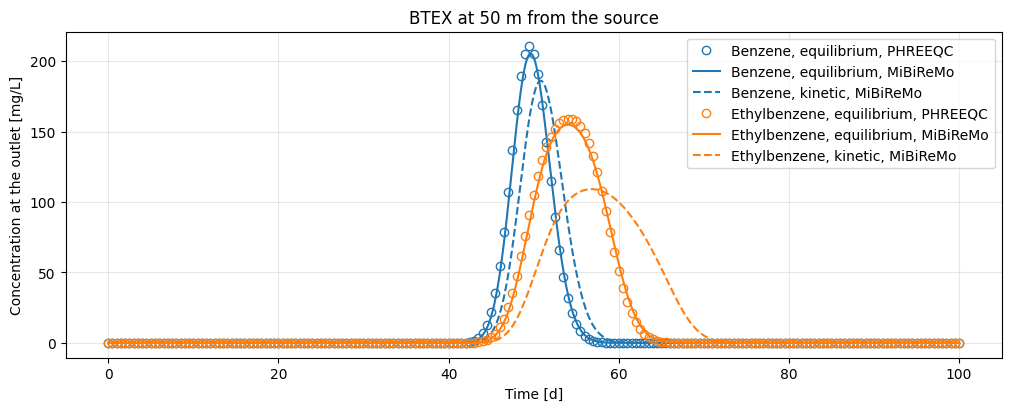

In [11]:
phreeqc = pd.read_csv(HERE / "pqi" / "column_BTEX_dissolution.sel", sep=r"\s+")
gfw = dict(zip(equilibrium.components, equilibrium.phreeqc.rm.GetGfw()))  # g/mol
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for component, name, color in [("Benz", "Benzene", "C0"), ("Ethyl", "Ethylbenzene", "C1")]:
    ax.plot(
        phreeqc["time"] / DAY,
        phreeqc[component] * 1e3 * gfw[component],
        "o",
        color=color,
        mfc="none",
        label=f"{name}, equilibrium, PHREEQC",
    )
    for model, case, style in [(equilibrium, "equilibrium", "-"), (kinetic, "kinetic", "--")]:
        effluent = model.effluent(component)
        ax.plot(
            effluent["time"] / DAY,
            effluent["concentration"] * gfw[component],
            style,
            color=color,
            label=f"{name}, {case}, MiBiReMo",
        )
ax.set(xlabel="Time [d]", ylabel="Concentration at the outlet [mg/L]", title="BTEX at 50 m from the source")
ax.grid(alpha=0.3)
ax.legend()
plt.show()